In [1]:
%matplotlib widget

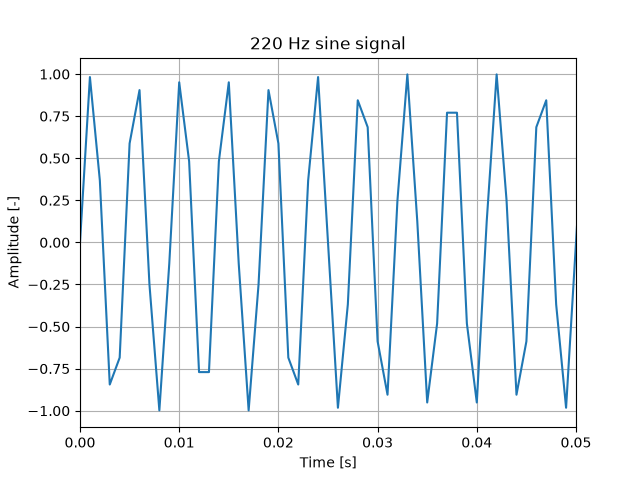

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import sounddevice as sd  # ty: ignore[unresolved-import]

# Parameters<
f = 220
fs = 1000
tmeas = 5

# Time vector and sine signal
t = np.arange(0, tmeas, 1 / fs)
y = np.sin(2 * np.pi * f * t)

# Plot the signal
plt.plot(t, y)
plt.xlabel("Time [s]")
plt.ylabel("Amplitude [-]")
plt.title("220 Hz sine signal")
plt.xlim(0, 0.05)  # Zoom in to see the waveform clearly
plt.grid()
plt.show()

# Play the signal
sd.play(y, samplerate=fs)
sd.wait()  # Wait until playback has finished

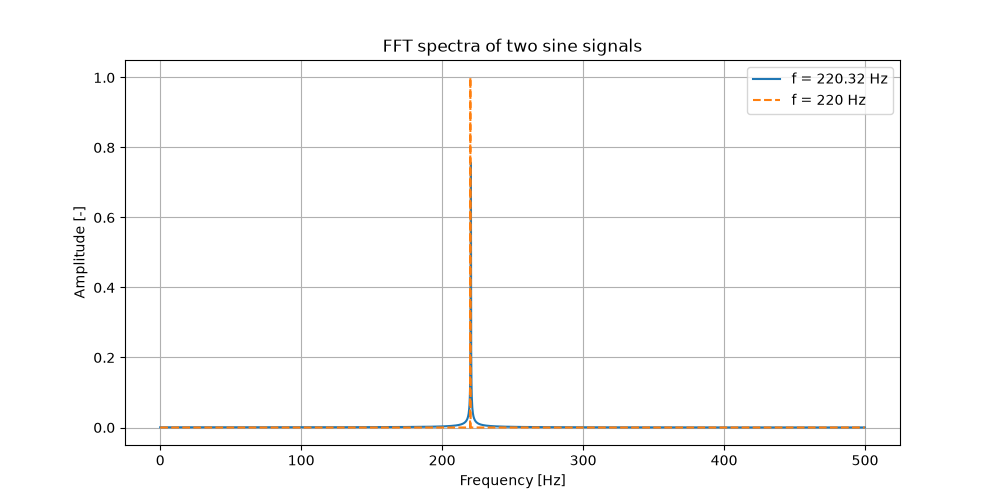

In [3]:
from scipy.fft import fft

# Parameters
fs = 1000       # Sampling frequency [Hz]
tmeas = 5       # Measuring time [s]
t = np.arange(0, tmeas, 1 / fs)

# Frequencies
f1 = 220.32
f2 = 220.0

# Sine signals
y1 = np.sin(2 * np.pi * f1 * t)
y2 = np.sin(2 * np.pi * f2 * t)

# Number of samples
N = np.size(y1)

# Frequency axis for the positive frequencies
freq = fs / N * np.arange(0, N // 2)

# FFT
Y1 = fft(y1)
Y2 = fft(y2)

# Single-sided amplitude spectra
Y1 = 2 * np.abs(Y1[0:N // 2]) / N
Y2 = 2 * np.abs(Y2[0:N // 2]) / N

# Plot FFT spectra
plt.figure(figsize=(10, 5))

plt.plot(freq, Y1, label="f = 220.32 Hz")
plt.plot(freq, Y2, "--", label="f = 220 Hz")

#plt.xlim(215, 225)
plt.xlabel("Frequency [Hz]")
plt.ylabel("Amplitude [-]")
plt.title("FFT spectra of two sine signals")
plt.grid()
plt.legend()
plt.show()

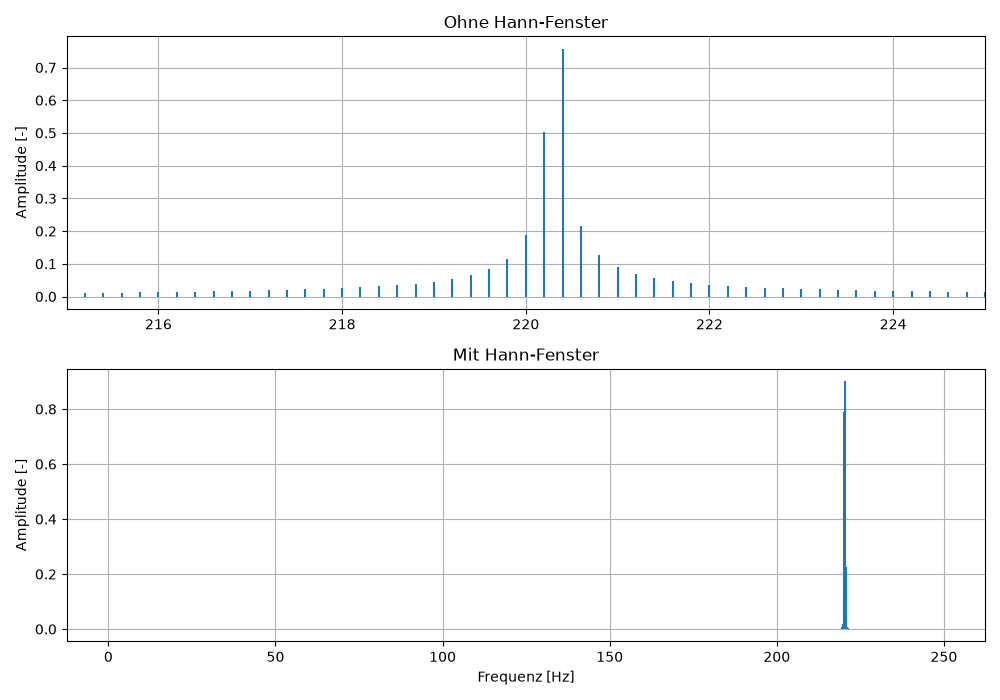

In [4]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.fft import fft

# Signalparameter
f = 220.32
fs = 500
tmeas = 5

# Zeitvektor und Signal
t = np.arange(0, tmeas, 1 / fs)
y = np.sin(2 * np.pi * f * t)

# Anzahl Samples und Frequenzachse
N = len(y)
freq = fs / N * np.arange(0, N // 2)

# FFT ohne Hann-Fenster
Y = fft(y)
Y_abs = 2 * np.abs(Y[:N // 2]) / N

# Hann-Fenster
win = np.hanning(N)
y_hann = y * win

# FFT mit Hann-Fenster
Y_hann = fft(y_hann)
Y_hann_abs = 2 * np.abs(Y_hann[:N // 2]) / np.sum(win)

# Stem-Diagramme
plt.figure(figsize=(10, 7))

plt.subplot(2, 1, 1)
plt.stem(freq, Y_abs, basefmt=" ", markerfmt=""),
plt.xlim(215, 225)
plt.ylabel("Amplitude [-]")
plt.title("Ohne Hann-Fenster")
plt.grid()

plt.subplot(2, 1, 2)
plt.stem(freq, Y_hann_abs, basefmt=" ", markerfmt=""),
#plt.xlim(215, 225)
plt.xlabel("Frequenz [Hz]")
plt.ylabel("Amplitude [-]")
plt.title("Mit Hann-Fenster")
plt.grid()

plt.tight_layout()
plt.show()

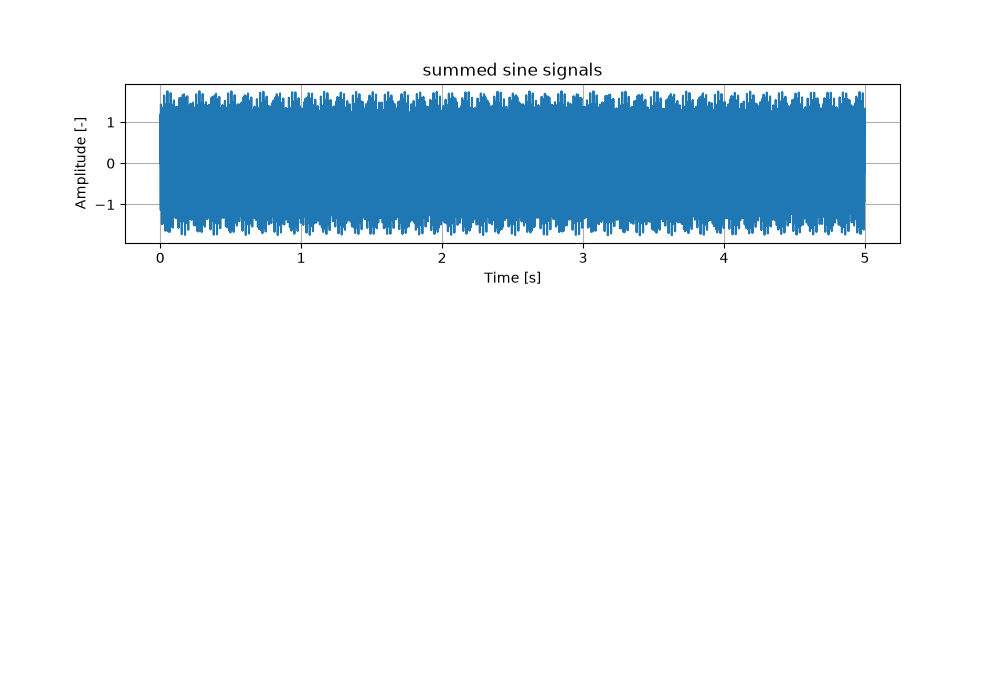

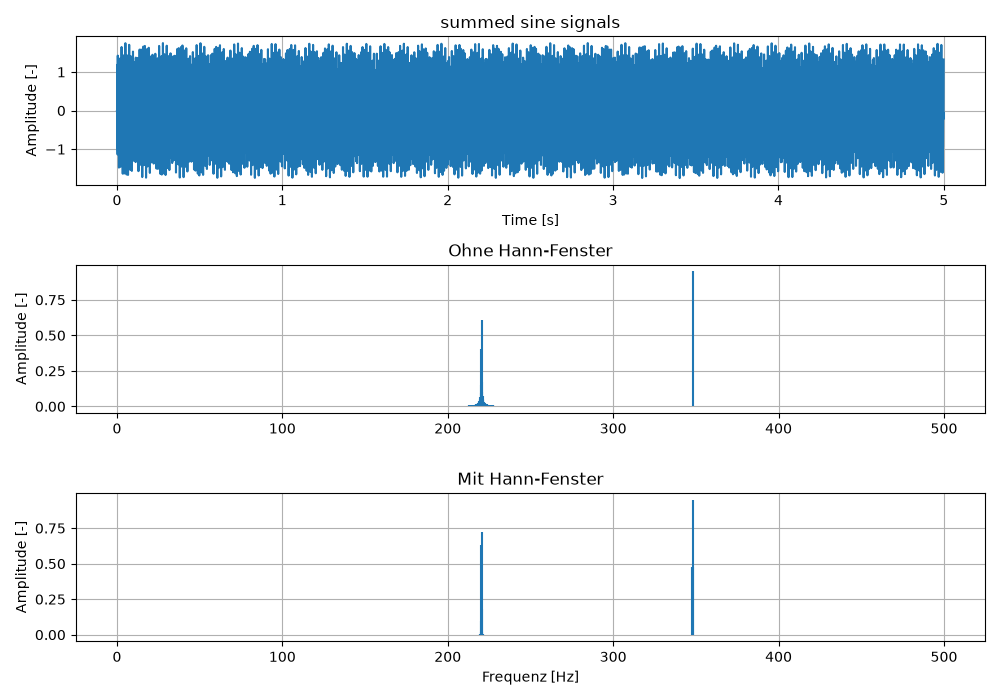

In [15]:
# Signalparameter
fs1 = 1000
f1 = 220.32
f2 = 652
A1 = 0.8
A2 = 0.95
tmeas = 5

# Zeitvektor und Signal
t_a = np.arange(0, tmeas, 1 / fs1)
y1 = A1 * np.sin(2 * np.pi * f1 * t_a)
y2 = A2 * np.sin(2 * np.pi * f2 * t_a)

y_sum = y1 + y2

# Anzahl Samples und Frequenzachse
N = len(y_sum)
freq = fs1 / N * np.arange(0, N // 2)

# FFT ohne Hann-Fenster
Y = fft(y_sum)
Y_abs = 2 * np.abs(Y[:N // 2]) / N

# Hann-Fenster
win = np.hanning(N)
y_hann = y_sum * win

# FFT mit Hann-Fenster
Y_hann = fft(y_hann)
Y_hann_abs = 2 * np.abs(Y_hann[:N // 2]) / np.sum(win)

# Stem-Diagramme
plt.figure(figsize=(10, 7))

# Plot the signal
plt.subplot(3, 1, 1)
plt.plot(t_a, y_sum)
plt.xlabel("Time [s]")
plt.ylabel("Amplitude [-]")
plt.title("summed sine signals")
#plt.xlim(0, 0.05)  # Zoom in to see the waveform clearly
plt.grid()
plt.show()

plt.subplot(3, 1, 2)
plt.stem(freq, Y_abs, basefmt=" ", markerfmt=""),
#plt.xlim(215, 225)
plt.ylabel("Amplitude [-]")
plt.title("Ohne Hann-Fenster")
plt.grid()

plt.subplot(3, 1, 3)
plt.stem(freq, Y_hann_abs, basefmt=" ", markerfmt=""),
#plt.xlim(215, 225)
plt.xlabel("Frequenz [Hz]")
plt.ylabel("Amplitude [-]")
plt.title("Mit Hann-Fenster")
plt.grid()

plt.tight_layout()
plt.show()


In [12]:
# Play the signal
#sd.play(y_sum, samplerate=fs1)
#sd.play(y1, samplerate=fs1)
sd.play(y2, samplerate=fs1)
sd.wait()  # Wait until playback has finished